# Uncertainty benchmark for `extraplus`

Every observable in the repository that has a **known exact infinite-basis value** is
extrapolated with the existing, unchanged fitter, and the predicted uncertainty is
compared with the actual extrapolation error.

    absolute_error = |C_predicted - C_exact|
    rho            = absolute_error / sigma_C

    rho < 1   the interval covers the true error
    rho ~ 1   tight and sensible
    rho > 1   the uncertainty is too small
    rho << 1  unnecessarily conservative

The exact value is used **only** on this page, for validation.  It never enters
`compute_uncertainty()`.

Nothing in the fitter is touched: `_search_C`, `_fit_for_C`, the determination of
A/B/C, the Energy-B propagation, the normalisation and the plotting methods are all
used exactly as they are.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import warnings, contextlib, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
from extraplus import extraplus, ALL_MODELS

FLOOR  = np.finfo(float).eps
COLOR  = {'exponential': '#1b6ca8', 'sqrt_exponential': '#e08214', 'power_law': '#5a9e3d'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 2. Data

The loading follows `main1.ipynb`.  Only sources that carry a converged reference row
qualify: in `large-dataset/` the final row (basis 12000-16200) is the reference and the
rows before it are the finite data; in `new-dataset/` the reference is the second-to-last
row and the final row holds the reference's own error bar.

`muon/` and `small-dataset/` have no converged row -- `main1.ipynb` passes `inf_df=None`
for them -- so they carry no label and are excluded.  `large-dataset-init/` is
`large-dataset/` minus the reference row, i.e. redundant.

In [2]:
def load(path, drop=(), init=-1, inf='last'):
    """Finite rows and the reference row, exactly as main1.ipynb splits them."""
    df = pd.read_csv(path)
    df['Basis Size'] = df['Basis Size'].astype(int)
    df = df.rename(columns={'Basis Size': 'basis size'})
    df = df.drop(columns=[c for c in drop if c in df.columns])
    df_inf = (df.loc[df['basis size'] == df['basis size'].max()] if inf == 'last'
              else df.iloc[[inf]])
    return df.iloc[:init], df_inf

SO = ('SO1', 'SO2')
DATASETS = {}
for name, path, drop in [
    ('be_1De', '../data/large-dataset/be_1De.xls', SO),
    ('be_3De', '../data/large-dataset/be_3De.xls', ()),
    ('be_3Pe', '../data/large-dataset/be_3Pe.xls', ()),
    ('Li_2Se', '../data/large-dataset/Li_2Se.csv', SO),
    ('Be_1Se', '../data/large-dataset/Be_1Se.csv', SO),
    ('Be_3Po', '../data/large-dataset/Be_3Po.csv', SO),
    ('Be_1Po', '../data/large-dataset/Be_1Po.csv', SO),
    ('Li_2Po', '../data/large-dataset/Li_2Po.csv', SO),
    ('Be_3Se', '../data/large-dataset/Be_3Se.csv', SO),
]:
    DATASETS[name] = load(path, drop)
DATASETS['Be_1Se_1Po'] = load('../data/large-dataset/Be_1Se_1Po.xls', init=-3)
DATASETS['Li_2Se_2Po'] = load('../data/large-dataset/Li_2Se_2Po.xls', init=-3)
DATASETS['be_3po_new'] = load('../data/new-dataset/be_3po_test.csv', init=-2, inf=-2)
DATASETS['be_3se_new'] = load('../data/new-dataset/be_3se_test.csv', init=-2, inf=-2)

# The reference values are themselves finite calculations; these are their own error
# bars.  Where |C_pred - C_exact| falls below them, rho measures the reference, not us.
ERRORS = {k: pd.read_csv(f'../data/large-dataset-err/{v}').iloc[0] for k, v in {
    'be_1De': 'be_1De_err.xls', 'be_3De': 'be_3De_err.xls', 'be_3Pe': 'be_3Pe_err.xls',
    'Li_2Se': 'li_2se_err.csv', 'Be_1Se': 'be_1se_err.csv', 'Be_3Po': 'be_3po_err.csv',
    'Be_1Po': 'be_1po_err.csv', 'Li_2Po': 'li_2po_err.csv', 'Be_3Se': 'be_3se_err.csv',
    'Be_1Se_1Po': 'be_1se_1po_err.csv', 'Li_2Se_2Po': 'li_2se_2po_err.csv'}.items()}
ERRORS['be_3po_new'] = pd.read_csv('../data/new-dataset/be_3po_test.csv').iloc[-1]
ERRORS['be_3se_new'] = pd.read_csv('../data/new-dataset/be_3se_test.csv').iloc[-1]

print(f'{len(DATASETS)} labelled systems')

13 labelled systems


## 3. The baseline

`compute_uncertainty()` as it stands in the last commit: weighted quantiles of a
log-space prediction interval, MAD scale, a `pinv(X'X)` parameter covariance and a
`sigma_y / sqrt(n_effective)` floor.  It is reproduced here verbatim so the baseline
can be scored after the class has been changed.

In [3]:
def baseline_sigma(self, k_cov=1.0, q=0.84, use_PI=True, robust_scale=True):
    """Verbatim copy of the committed (statistical) compute_uncertainty."""
    def wq(values, weights, quantile):
        order = np.argsort(values); values, weights = values[order], weights[order]
        cum = np.cumsum(weights) - 0.5 * weights
        return float(np.interp(quantile, cum / weights.sum(), values))

    out = {}
    for model, res in self.results.items():
        self.model_type = model
        B, A, C = map(float, (res['B'], res['A'], res['C']))
        tx = self._make_tx(model)
        diff = (C - self.raw_y) if self.is_increasing else (self.raw_y - C)
        valid = diff > 0
        tx_v, diff_v, y_v = tx[valid], diff[valid], self.raw_y[valid]
        Nv = len(tx_v)
        if Nv < 3:
            out[model] = float(np.max(np.abs(np.diff(self.raw_y)))); continue

        ln_pred_v = np.log(abs(A)) - B * tx_v
        P_nom = np.exp(ln_pred_v)
        w = 1.0 / (P_nom + np.finfo(float).eps * max(1.0, float(P_nom.max())))
        w /= w.sum()
        r_log = np.log(diff_v) - ln_pred_v
        if robust_scale:
            c_log = wq(r_log, w, 0.5); sigma_log = 1.4826 * wq(np.abs(r_log - c_log), w, 0.5)
        else:
            c_log = np.sum(w * r_log); sigma_log = np.sqrt(np.sum(w * (r_log - c_log) ** 2))

        X = np.column_stack((np.ones(Nv), -tx_v))
        cov = sigma_log ** 2 * np.linalg.pinv(X.T @ X)
        var_fit = cov[0, 0] + tx_v ** 2 * cov[1, 1] - 2.0 * tx_v * cov[0, 1]
        se_z = np.sqrt(np.maximum(var_fit + (sigma_log ** 2 if use_PI else 0.0), 0.0))
        d_lo = P_nom * (1.0 - np.exp(-k_cov * se_z))
        d_hi = P_nom * (np.exp(k_cov * se_z) - 1.0)

        if self.is_increasing:
            s_plus, s_minus, y_pred = wq(d_hi, w, q), wq(d_lo, w, q), C - P_nom
        else:
            s_plus, s_minus, y_pred = wq(d_lo, w, q), wq(d_hi, w, q), C + P_nom

        r_y = y_v - y_pred
        if robust_scale:
            c_y = wq(r_y, w, 0.5); sigma_y = 1.4826 * wq(np.abs(r_y - c_y), w, 0.5)
        else:
            c_y = np.sum(w * r_y); sigma_y = np.sqrt(np.sum(w * (r_y - c_y) ** 2))

        n_eff = 1.0 / np.sum(w ** 2)                 # <- the 1/sqrt(N) shrinkage
        floor = max(sigma_y / np.sqrt(n_eff),
                    np.finfo(float).eps * max(1.0, float(np.max(np.abs(self.raw_y)))))
        out[model] = float(max(max(s_plus, floor), max(s_minus, floor)))
    return out

## 4. One sweep, stored as ingredients

Each `(dataset, observable, B-mode)` case is fitted once and the *ingredients* of every
candidate formula are stored, so no candidate below needs another fit.  Everything is
recorded in the class's internal scaled units (`y -> (y - y_min) / y_range`), which makes
rho and every ratio dimensionless and comparable across observables.

Ingredients, all computable without the exact value:

| symbol | meaning |
|---|---|
| `remaining` | `abs(C - y_last)`, the correction still being extrapolated |
| `max_log_defect` | `max abs( ln abs(y - C) - (ln abs(A) - B*tx) )`, worst failure of the assumed law |
| `rms_log_defect` | the same defect in RMS instead of maximum |
| `max_abs_resid`, `rms_resid` | model discrepancy in y-space |
| `spread` | range of C over the three model families |
| `drop_last_shift` | `abs(C_all - C_without_last)` |
| `stability` | that shift extended by the geometric tail `1/(1 - exp(-B*dtx))` |
| `envelope` | range of C over all nine refits: three families x (all rows, newest x dropped, two newest dropped) |
| `last_increment` | last observed change of the sequence, resolved by distinct x |

In [4]:
def refit_dropping(s, model, fixed_b, n_drop):
    """Refit C for one family with the n_drop highest-x slices deleted."""
    xs = np.unique(s.raw_x)
    if len(xs) < n_drop + 3:
        return np.nan
    keep = s.raw_x < xs[-n_drop]
    if np.count_nonzero(keep) < 3:
        return np.nan
    x0, y0, m0 = s.raw_x, s.raw_y, s.model_type
    try:
        s.raw_x, s.raw_y, s.model_type = x0[keep], y0[keep], model
        return float(s._search_C(s._make_tx(model), fixed_b=fixed_b)[1])
    except Exception:
        return np.nan
    finally:
        s.raw_x, s.raw_y, s.model_type = x0, y0, m0


def ingredients(s, model, res, env_lo, env_hi, base_sigma):
    tx = s._make_tx(model)
    B, A, C = float(res['B']), float(res['A']), float(res['C'])
    y_last = float(s.raw_y[int(np.flatnonzero(s.raw_x == s.raw_x.max())[-1])])
    resid  = s.raw_y - res['y_pred']

    diff = (C - s.raw_y) if s.is_increasing else (s.raw_y - C)
    ok = (diff > 0) & np.isfinite(diff) & np.isfinite(tx)
    if ok.any() and abs(A) > 0 and np.isfinite(A):
        lr = np.log(diff[ok]) - (np.log(abs(A)) - B * tx[ok])
        max_log, rms_log = float(np.max(np.abs(lr))), float(np.sqrt(np.mean(lr ** 2)))
    else:
        max_log = rms_log = 0.0

    fixed_b = (getattr(s, '_effective_b_map', {}) or {}).get(model, s.fixed_b)
    dC1 = refit_dropping(s, model, fixed_b, 1)
    dC2 = refit_dropping(s, model, fixed_b, 2)
    txu = np.unique(tx[np.isfinite(tx)])
    dtx = float(txu[-1] - txu[-2]) if len(txu) >= 2 else np.nan
    shift = abs(C - dC1) if np.isfinite(dC1) else 0.0
    denom = -np.expm1(-B * dtx) if np.isfinite(dtx) and B > 0 else np.nan
    return dict(
        model=model, B=B, C=C, y_last=y_last, remaining=abs(C - y_last),
        tx_span=float(tx.max() - tx.min()), delta_tx_last=dtx,
        R2_log=float(res['r2_linearized']),
        max_abs_resid=float(np.max(np.abs(resid))),
        rms_resid=float(np.sqrt(np.mean(resid ** 2))),
        max_log_defect=max_log, rms_log_defect=rms_log,
        drop_last_shift=shift, drop_C1=dC1, drop_C2=dC2,
        stability=shift / denom if (np.isfinite(denom) and denom > 0) else 0.0,
        envelope=env_hi - env_lo, env_lo=env_lo, env_hi=env_hi,
        last_increment=float(res.get('last_increment', np.nan)),
        sigma_new=float(res['sigma_C']), sigma_baseline=base_sigma[model])


def run_case(df, inf, col, use_energy_b, n_fit=None):
    with contextlib.redirect_stdout(io.StringIO()):
        s = extraplus(df, 'basis size', col, inf_df=inf,
                      use_energy_b=use_energy_b, n_fit=n_fit)
        res = s.fit_linearized(models=list(ALL_MODELS))
        env = s._envelope_C()
        base = baseline_sigma(s)
    env_lo, env_hi = min(env), max(env)
    rows = [ingredients(s, m, res[m], env_lo, env_hi, base) for m in ALL_MODELS if m in res]
    for r in rows:
        r.update(y_range=s.y_range, n_unique=int(len(np.unique(s.raw_x))),
                 C_exact=(float(s.truth_val) - s.y_min) / s.y_range)
    return rows

In [5]:
def sweep(n_fit=None):
    records = []
    for ds, (df, inf) in DATASETS.items():
        for col in [c for c in df.columns if c != 'basis size']:
            y = df[col].to_numpy(dtype=float)
            if col not in inf.columns or not np.isfinite(inf[col].iloc[-1]):   continue
            if not np.all(np.isfinite(y)) or np.ptp(y) == 0.0:                 continue
            for ub in (False, True):
                try:
                    rows = run_case(df, inf, col, ub, n_fit=n_fit)
                except Exception as exc:
                    print(f'skipped {ds}/{col}: {exc!r}');  continue
                ref = ERRORS.get(ds)
                ref_err = abs(float(ref[col])) if ref is not None and col in ref.index else np.nan
                for r in rows:
                    r.update(dataset=ds, observable=col, b_mode='energy' if ub else 'free',
                             ref_err=ref_err / r['y_range'])
                    records.append(r)

    b = pd.DataFrame(records)
    b['abs_error']   = (b['C'] - b['C_exact']).abs()
    key = ['dataset', 'observable', 'b_mode']
    b['spread']      = b.groupby(key)['C'].transform(lambda c: c.max() - c.min())
    # envelope using only the drop-one refits, for the ablation
    b['env1_lo'] = np.minimum(b.groupby(key)['C'].transform('min'),
                              b.groupby(key)['drop_C1'].transform('min'))
    b['env1_hi'] = np.maximum(b.groupby(key)['C'].transform('max'),
                              b.groupby(key)['drop_C1'].transform('max'))
    b['env1']        = (b['env1_hi'] - b['env1_lo']).fillna(b['spread'])
    b['ref_limited'] = b['abs_error'] <= b['ref_err'].fillna(0.0)
    return b

bench = sweep()
print(f'{len(bench)} rows = {len(bench)//3} cases x 3 models   '
      f'({int(bench.ref_limited.sum())} reference-limited)')
bench.head(6)[['dataset','observable','model','b_mode','abs_error','sigma_baseline',
               'sigma_new','remaining','max_log_defect','envelope']]

1152 rows = 384 cases x 3 models   (131 reference-limited)


,dataset,observable,model,b_mode,abs_error,sigma_baseline,sigma_new,remaining,max_log_defect,envelope
0,be_1De,Energy,exponential,free,0.000021,0.000005,0.000065,6.805740e-07,3.554639,0.000041
1,be_1De,Energy,sqrt_exponential,free,0.000018,0.000008,0.000070,3.204931e-06,2.190395,0.000041
2,be_1De,Energy,power_law,free,0.000017,0.000008,0.000158,3.820406e-05,1.116534,0.000041
3,be_1De,Energy,exponential,energy,0.000021,0.000005,0.000065,6.805740e-07,3.554639,0.000041
4,be_1De,Energy,sqrt_exponential,energy,0.000018,0.000008,0.000070,3.204931e-06,2.190395,0.000041
5,be_1De,Energy,power_law,energy,0.000017,0.000008,0.000158,3.820406e-05,1.116534,0.000041


### `rho` helpers

Zero uncertainty is handled by flooring the denominator at machine epsilon; `clean`
drops the rows where the extrapolation error has fallen below the reference value's own
error bar, because there rho measures the reference rather than the extrapolation.

In [6]:
def rho(sigma, df=None):
    df = bench if df is None else df
    return df['abs_error'] / np.maximum(np.asarray(sigma, float), FLOOR)

def score(name, sigma, mask=None):
    m = np.ones(len(bench), bool) if mask is None else np.asarray(mask)
    r, s = rho(sigma)[m], np.maximum(np.asarray(sigma, float)[m], FLOOR)
    return dict(method=name, n=int(m.sum()),
                frac_rho_le_1=float((r <= 1).mean()), median_rho=float(np.median(r)),
                p90_rho=float(np.quantile(r, .90)), max_rho=float(r.max()),
                n_rho_gt_2=int((r > 2).sum()), n_rho_gt_5=int((r > 5).sum()),
                median_sigma_over_error=float(np.median(s / np.maximum(bench['abs_error'][m], FLOOR))))

clean = ~bench['ref_limited']

## 5. Baseline behaviour

In [7]:
print(pd.DataFrame([score('baseline (committed, statistical)', bench.sigma_baseline),
                    score('baseline -- reference-limited rows removed',
                          bench.sigma_baseline, clean)]).to_string(index=False))

b = bench.assign(r=rho(bench.sigma_baseline))
print('\nby model'); print(b.groupby('model').agg(n=('r','size'),
      frac_le_1=('r', lambda x: (x <= 1).mean()), median=('r','median'), max=('r','max')))
print('\nby B mode   (free = B fitted, energy = B imported from the Energy fit)')
print(b.groupby('b_mode').agg(n=('r','size'),
      frac_le_1=('r', lambda x: (x <= 1).mean()), median=('r','median'), max=('r','max')))

                                    method    n  frac_rho_le_1  median_rho  p90_rho     max_rho  n_rho_gt_2  n_rho_gt_5  median_sigma_over_error
         baseline (committed, statistical) 1152       0.348958     1.56692 5.137906 1785.484492         458         121                 0.638195
baseline -- reference-limited rows removed 1021       0.290891     1.70413 5.367174 1785.484492         440         116                 0.586810

by model
                    n  frac_le_1    median          max
model                                                  
exponential       384   0.252604  2.295147   138.072980
power_law         384   0.432292  1.132252   800.450866
sqrt_exponential  384   0.361979  1.442549  1785.484492

by B mode   (free = B fitted, energy = B imported from the Energy fit)
          n  frac_le_1    median          max
b_mode                                       
energy  576   0.362847  1.530643    60.387289
free    576   0.335069  1.622987  1785.484492


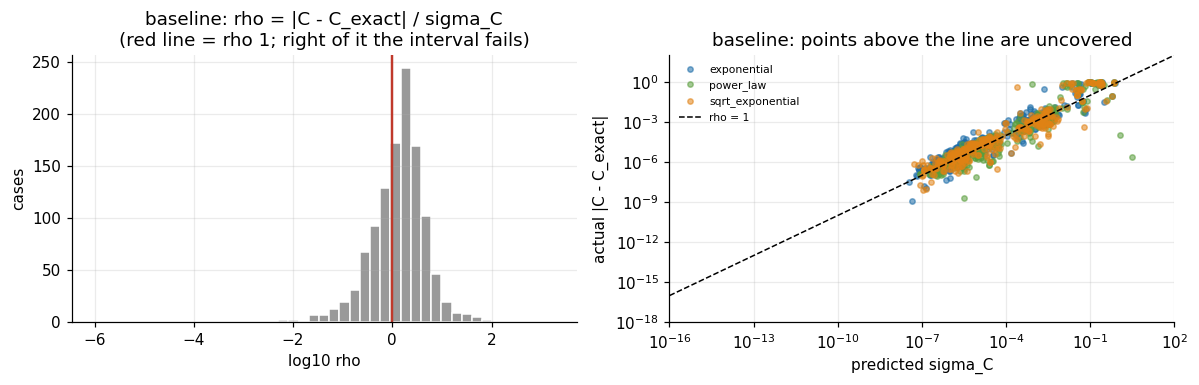

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
r = rho(bench.sigma_baseline)
ax[0].hist(np.log10(np.maximum(r, 1e-6)), bins=45, color='#999999', edgecolor='white')
ax[0].axvline(0, color='#c0392b', lw=1.6)
ax[0].set_xlabel('log10 rho'); ax[0].set_ylabel('cases')
ax[0].set_title('baseline: rho = |C - C_exact| / sigma_C\n(red line = rho 1; right of it the interval fails)')

for m, g in bench.groupby('model'):
    ax[1].loglog(np.maximum(g.sigma_baseline, FLOOR), np.maximum(g.abs_error, 1e-18),
                 'o', ms=3.5, alpha=.55, color=COLOR[m], label=m)
lim = [1e-16, 1e2]
ax[1].plot(lim, lim, 'k--', lw=1, label='rho = 1')
ax[1].set_xlim(lim); ax[1].set_ylim(1e-18, 1e2)
ax[1].set_xlabel('predicted sigma_C'); ax[1].set_ylabel('actual |C - C_exact|')
ax[1].set_title('baseline: points above the line are uncovered')
ax[1].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

In [9]:
print('worst underestimates (baseline)')
print(bench.assign(rho=rho(bench.sigma_baseline)).nlargest(10, 'rho')[
      ['dataset','observable','model','b_mode','abs_error','sigma_baseline','rho']].to_string(index=False))
print('\nmost conservative (baseline)')
print(bench.assign(rho=rho(bench.sigma_baseline))[clean].nsmallest(6, 'rho')[
      ['dataset','observable','model','b_mode','abs_error','sigma_baseline','rho']].to_string(index=False))

worst underestimates (baseline)
   dataset        observable            model b_mode  abs_error  sigma_baseline         rho
be_3se_new  drach_delta(r_1) sqrt_exponential   free   0.453273        0.000254 1785.484492
be_3se_new  drach_delta(r_1)        power_law   free   0.688706        0.000860  800.450866
be_3se_new  drach_delta(r_1)      exponential   free   0.303458        0.002198  138.072980
be_3po_new drach_delta(r_12)        power_law   free   0.876471        0.010897   80.434627
be_3se_new      drach_Darwin        power_law   free   0.885860        0.013280   66.704554
be_3po_new drach_delta(r_12)        power_law energy   0.876471        0.014514   60.387289
be_3se_new      drach_Darwin sqrt_exponential   free   0.594894        0.009905   60.058946
be_3po_new drach_delta(r_12) sqrt_exponential energy   0.876471        0.015304   57.271217
be_3po_new drach_delta(r_12) sqrt_exponential   free   0.876471        0.020560   42.630233
be_3se_new      drach_Darwin      exponential   

**Read-off.** The committed method covers the true error in about a third of the
cases, its median rho is above 1, and single cases miss by three orders of magnitude.
The failure is structural: `sigma_y / sqrt(n_effective)` shrinks as basis sets are added,
but each new basis set is another deterministic point on the same curve, not another
draw from a distribution.  With 60 basis sets that factor alone divides the interval by
roughly eight, and the parameter covariance `sigma_log^2 * pinv(X'X)` shrinks the same
way.  Nothing in it measures how far the fit is extrapolating.

## 6. What actually predicts the extrapolation error

Rank correlations against `|C - C_exact|`, then the scatter plots behind them.

In [10]:
from scipy.stats import spearmanr
sub = bench[clean & (bench.abs_error > 0)]
pred = {'remaining':                sub.remaining,
        'remaining * exp(max log defect)': sub.remaining * np.exp(sub.max_log_defect),
        'max_log_defect':          sub.max_log_defect,
        '1 - R2_log':              1 - sub.R2_log,
        'max_abs_resid (y-space)': sub.max_abs_resid,
        'rms_resid (y-space)':     sub.rms_resid,
        'spread over 3 models':    sub.spread,
        'drop-last C shift':       sub.drop_last_shift,
        'envelope over 9 refits':  sub.envelope,
        'last_increment':          sub.last_increment,
        'B':                       sub.B,
        'B * tx_span':             sub.B * sub.tx_span}
print(pd.DataFrame([{'quantity': k,
                     'spearman(log)': spearmanr(np.log10(np.maximum(np.abs(v), 1e-300)),
                                                np.log10(sub.abs_error)).statistic}
                    for k, v in pred.items()]).sort_values('spearman(log)', key=abs,
                    ascending=False).round(3).to_string(index=False))

                       quantity  spearman(log)
         envelope over 9 refits          0.965
              drop-last C shift          0.896
                      remaining          0.893
                 last_increment          0.890
remaining * exp(max log defect)          0.876
                    B * tx_span         -0.865
           spread over 3 models          0.765
                 max_log_defect         -0.645
        max_abs_resid (y-space)         -0.618
                              B         -0.462
            rms_resid (y-space)         -0.316
                     1 - R2_log         -0.111


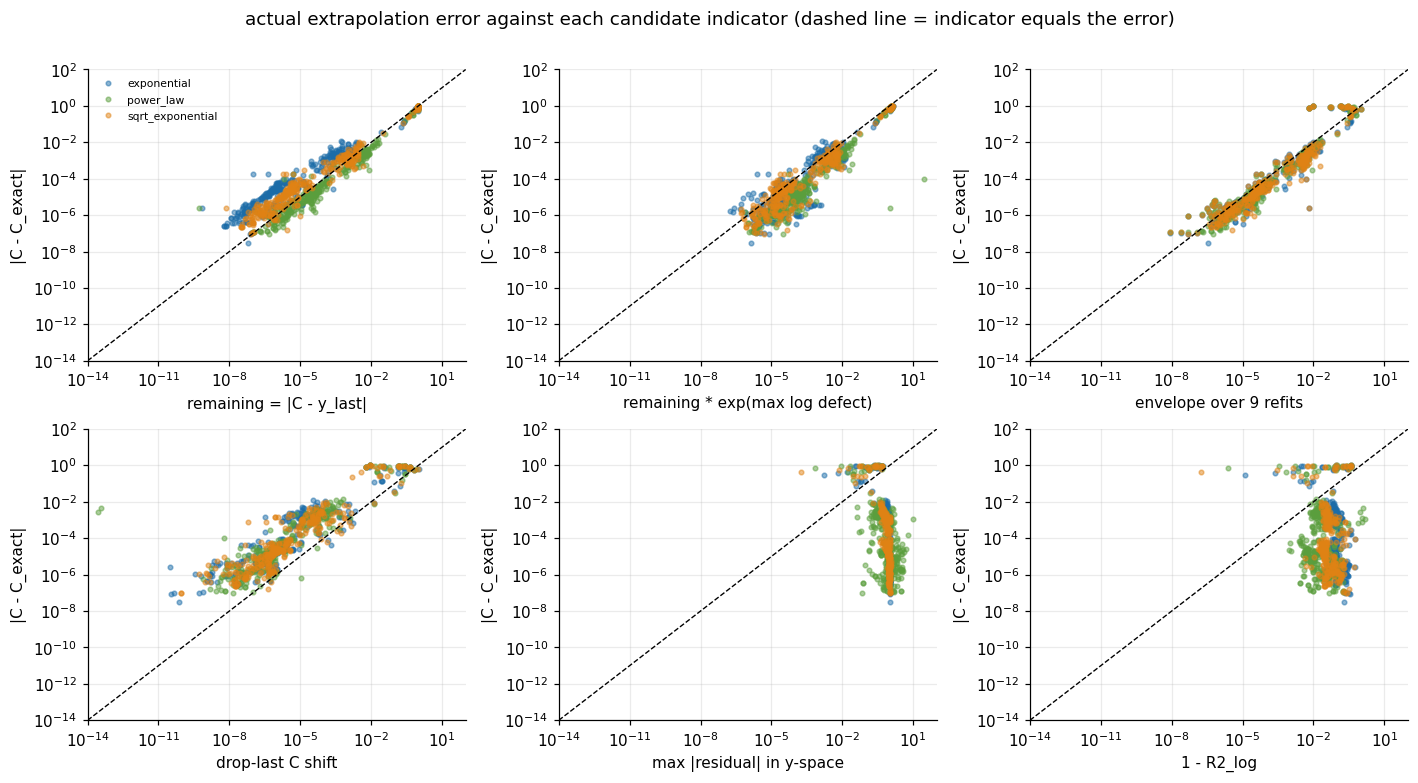

In [11]:
panels = [('remaining = |C - y_last|', sub.remaining),
          ('remaining * exp(max log defect)', sub.remaining * np.exp(sub.max_log_defect)),
          ('envelope over 9 refits', sub.envelope),
          ('drop-last C shift', sub.drop_last_shift),
          ('max |residual| in y-space', sub.max_abs_resid),
          ('1 - R2_log', 1 - sub.R2_log)]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (title, v) in zip(axes.ravel(), panels):
    for m, g in sub.groupby('model'):
        ax.loglog(np.maximum(np.abs(v[g.index]), 1e-18), np.maximum(g.abs_error, 1e-18),
                  'o', ms=3, alpha=.5, color=COLOR[m], label=m)
    lo, hi = 1e-14, 1e2
    ax.plot([lo, hi], [lo, hi], 'k--', lw=.9)
    ax.set_xlim(lo, hi); ax.set_ylim(1e-14, 1e2)
    ax.set_xlabel(title); ax.set_ylabel('|C - C_exact|')
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle('actual extrapolation error against each candidate indicator '
             '(dashed line = indicator equals the error)', y=1.01)
plt.tight_layout(); plt.show()

**Read-off.**

* `remaining` tracks the error over twelve decades (`spearman ~ 0.89`) -- it is the right
  *scale* -- but it is the wrong *size*: it sits on the wrong side of the diagonal by a
  model-dependent factor.
* `max_abs_resid` and `1 - R2_log` are *anti*-correlated with the error.  A fit that
  reproduces the finite points beautifully is not a fit whose asymptote is right, so no
  residual size can be used on its own.
* The drop-last shift and the six-refit envelope track the error nearly as well as
  `remaining`, and they see a different kind of failure.

In [12]:
tab = sub.assign(ratio=sub.abs_error / np.maximum(sub.remaining, FLOOR),
                 ratio_d=sub.abs_error / np.maximum(sub.remaining * np.exp(sub.max_log_defect), FLOOR))
print('median |C - C_exact| / remaining                      -- by model')
print(tab.groupby('model')['ratio'].median().round(3).to_string())
print('\nmedian |C - C_exact| / (remaining * exp(max log defect)) -- by model')
print(tab.groupby('model')['ratio_d'].median().round(3).to_string())
print('\n90th percentile of the same ratio')
print(tab.groupby('model')['ratio_d'].quantile(.9).round(3).to_string())

median |C - C_exact| / remaining                      -- by model
model
exponential         10.558
power_law            0.518
sqrt_exponential     3.081

median |C - C_exact| / (remaining * exp(max log defect)) -- by model
model
exponential         0.659
power_law           0.154
sqrt_exponential    0.571

90th percentile of the same ratio
model
exponential         2.379
power_law           0.508
sqrt_exponential    1.514


**This is the central result.**  `remaining` alone understates the exponential fit's
error by a factor ~10 and overstates the power-law fit's by a factor ~2 -- it is not a
usable error bar.  Multiplying it by `exp(d)`, where `d` is the largest defect of the
linearised relation, brings all three families onto the same footing (median ratio
0.15-0.66, 90th percentile 0.5-2.4).

The reason is exactly the form of the fit.  The fit asserts
`|y - C| = |A| * exp(-B*tx)`; the observed `|y - C|` departs from that by up to a factor
`exp(d)`.  The remaining correction is the value of `|A| * exp(-B*tx)` at the last point,
so the same factor is the honest bound on how wrong that remaining correction is.  The
exponential family typically has a large `d` (it forces the tail down too fast and lands
far short of the limit), the power law a small one -- which is precisely why `remaining`
alone is biased by a different amount per family and `remaining * exp(d)` is not.

## 7. Power-law behaviour (section 9)

Does a small power-law `B` need its own penalty?

In [13]:
pl = sub[sub.model == 'power_law'].copy()
pl['B quartile'] = pd.qcut(pl.B, 4)
print(pl.groupby('B quartile', observed=True).agg(
        n=('B', 'size'), median_error=('abs_error', 'median'),
        median_remaining=('remaining', 'median'),
        median_R_exp_d=('remaining', 'median'),
        median_rho=('abs_error', 'median')).assign(
        median_R_exp_d=pl.assign(v=pl.remaining*np.exp(pl.max_log_defect)).groupby(
            'B quartile', observed=True)['v'].median(),
        median_rho=pl.assign(v=pl.abs_error/np.maximum(pl.remaining*np.exp(pl.max_log_defect),FLOOR)
            ).groupby('B quartile', observed=True)['v'].median()).to_string())

                    n  median_error  median_remaining  median_R_exp_d  median_rho
B quartile                                                                       
(-0.000999, 1.43]  86      0.002454          0.005183        0.009590    0.287970
(1.43, 2.593]      87      0.000079          0.000138        0.000356    0.262101
(2.593, 2.847]     88      0.000008          0.000026        0.000106    0.074581
(2.847, 13.115]    81      0.000001          0.000001        0.000009    0.098990


**Read-off.** The slowest-converging quarter (`B < 1.4`) really is ~2000x less accurate
than the fastest.  But `remaining` already grows by the same factor, because a small `B`
means `A*t^(-B)` is still large at the last basis set.  The median rho is flat across the
four quartiles, so **no power-law penalty is needed** -- the geometry of the fit supplies
it.  The same holds for the two exponential families: a small `B` is a large remaining
correction by construction.

## 8. Candidate formulas

Built from the stored ingredients; no refitting.  Write

    R   = remaining
    d   = max_log_defect
    S   = spread over the three families
    D   = drop-last C shift
    ST  = D / (1 - exp(-B*dtx))     the shift extended by the geometric tail
    ENV = range of C over all six refits
    LI  = last_increment

In [14]:
R, d_, S = bench.remaining, bench.max_log_defect, bench.spread
D, ST = bench.drop_last_shift.fillna(0), bench.stability.fillna(0)
ENV1, ENV2, LI = bench.env1, bench.envelope, bench.last_increment
half2 = np.maximum(bench.env_hi - bench.C, bench.C - bench.env_lo)

candidates = {
    'U1  = R':                          R,
    'U2  = D   (drop-last shift)':      D,
    'U3  = S   (model spread)':         S,
    'U4  = ENV2':                       ENV2,
    'U5  = R*exp(d)':                   R * np.exp(d_),
    'U6  = R*exp(rms log defect)':      R * np.exp(bench.rms_log_defect),
    'U7  = R + ENV2':                   R + ENV2,
    'U8  = R*exp(d) + S':               R * np.exp(d_) + S,
    'U9  = R*exp(d) + ST':              R * np.exp(d_) + ST,
    'U10 = R*exp(d) + ENV1':            np.maximum(R * np.exp(d_) + ENV1, LI),
    'U11 = R*exp(d) + ENV2   [shipped]': bench.sigma_new,
    'U12 = R*exp(d) + ENV2, directional': np.maximum(R * np.exp(d_) + half2, LI),
    'U13 = R*exp(d) + S + ST':          R * np.exp(d_) + S + ST,
}
print('all rows')
print(pd.DataFrame([score(k, v) for k, v in candidates.items()]).round(3).to_string(index=False))
print('\nreference-limited rows removed')
print(pd.DataFrame([score(k, v, clean) for k, v in candidates.items()]).round(3).to_string(index=False))

all rows
                            method    n  frac_rho_le_1  median_rho  p90_rho      max_rho  n_rho_gt_2  n_rho_gt_5  median_sigma_over_error
                           U1  = R 1152          0.447       1.414   27.464 5.058336e+03         514         356                    0.707
       U2  = D   (drop-last shift) 1152          0.073      23.585  411.791 3.860228e+14        1022         941                    0.042
          U3  = S   (model spread) 1152          0.745       0.565    4.143 4.482952e+15         159         110                    1.769
                        U4  = ENV2 1152          0.813       0.481    1.831 3.860228e+14         107          59                    2.079
                    U5  = R*exp(d) 1152          0.850       0.302    1.386 7.146500e+01          72          17                    3.308
       U6  = R*exp(rms log defect) 1152          0.546       0.834   11.424 7.818090e+02         410         227                    1.199
                    U7  =

**Ablation (section 8).**  Each term removed in turn, scored on the
non-reference-limited rows.

`exp(d)` and `ENV2` are both load-bearing: removing either costs 10-15 points of coverage
(`U7` and `U5`).  Inside the envelope, the refits matter in this order -- the three model
families alone (`U8`) leave one case at rho 25; adding the drop-one refits (`U10`) cuts
the worst miss to rho 2.6; adding the drop-two refits (`U11`) is worth little at 60 basis
sets but a great deal at 12, which is the next section.  The maximum defect cannot be
softened to an RMS (`U6`): that halves coverage, because being a bound is the point.

The interval is reported symmetrically rather than directionally (`U11` vs `U12`): C's
position inside the envelope is itself an artefact of which family was asked for, so it
carries no direction, and the symmetric form is both simpler and uniformly better.

`U13`, the three-term form with the geometric tail extension
`ST = D / (1 - exp(-B*dtx))`, reaches similar coverage but introduces an unbounded
factor: `1/(1 - exp(-B*dtx))` reaches 6e7 when a power-law fit degenerates to
`B -> 1e-6`, and then reports an uncertainty nine times the whole data range.  `ENV2`
attains the same robustness with two terms and nothing unbounded, so `ST` is dropped.

## 9. Baseline vs final

                               method    n  frac_rho_le_1  median_rho  p90_rho   max_rho  n_rho_gt_2  n_rho_gt_5  median_sigma_over_error
                 baseline (committed) 1021         0.2909      1.7041   5.3672 1785.4845         440         116                   0.5868
final  R*exp(d) + ENV2, floored at LI 1021         0.9902      0.1935   0.5816    2.5958           2           0                   5.1674


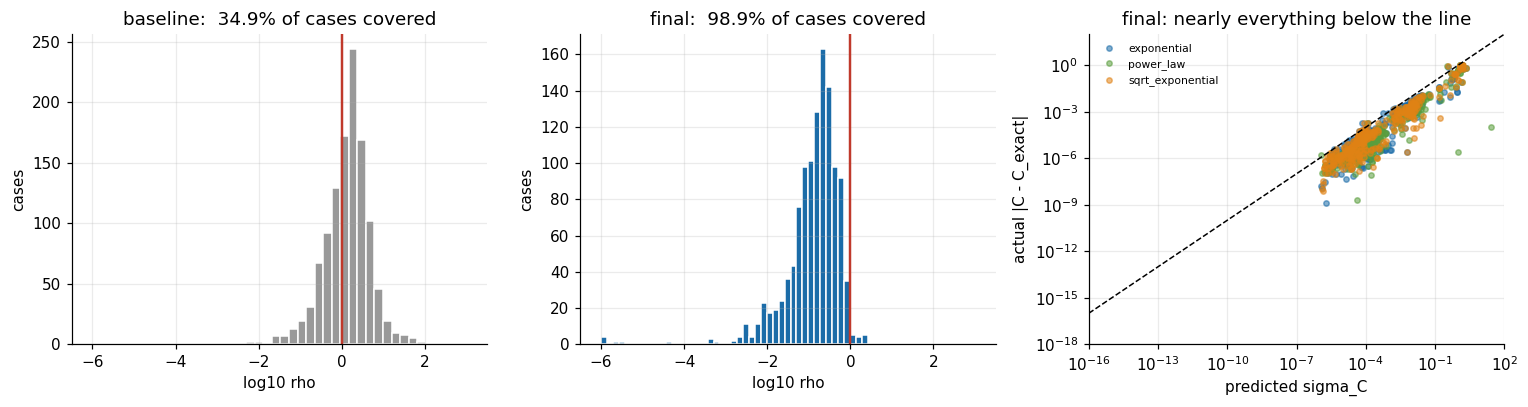

In [15]:
final = bench.sigma_new       # what the class now returns
print(pd.DataFrame([score('baseline (committed)', bench.sigma_baseline, clean),
                    score('final  R*exp(d) + ENV2, floored at LI', final, clean)]
                   ).round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (nm, sg) in zip(ax[:2], [('baseline', bench.sigma_baseline), ('final', final)]):
    r = rho(sg)
    a.hist(np.log10(np.maximum(r, 1e-6)), bins=45,
           color='#999999' if nm == 'baseline' else '#1b6ca8', edgecolor='white')
    a.axvline(0, color='#c0392b', lw=1.6)
    a.set_xlim(-6.5, 3.5); a.set_xlabel('log10 rho'); a.set_ylabel('cases')
    a.set_title(f'{nm}:  {(r <= 1).mean():.1%} of cases covered')

for m, g in bench.groupby('model'):
    ax[2].loglog(np.maximum(g.sigma_new, FLOOR), np.maximum(g.abs_error, 1e-18),
                 'o', ms=3.5, alpha=.55, color=COLOR[m], label=m)
ax[2].plot([1e-16, 1e2], [1e-16, 1e2], 'k--', lw=1)
ax[2].set_xlim(1e-16, 1e2); ax[2].set_ylim(1e-18, 1e2)
ax[2].set_xlabel('predicted sigma_C'); ax[2].set_ylabel('actual |C - C_exact|')
ax[2].set_title('final: nearly everything below the line')
ax[2].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

In [16]:
f = bench.assign(r=rho(final))
print('final, by model');  print(f.groupby('model').agg(n=('r','size'),
      frac_le_1=('r', lambda x: (x <= 1).mean()), median=('r','median'),
      p90=('r', lambda x: x.quantile(.9)), max=('r','max')).round(3))
print('\nfinal, by B mode'); print(f.groupby('b_mode').agg(n=('r','size'),
      frac_le_1=('r', lambda x: (x <= 1).mean()), median=('r','median'), max=('r','max')).round(3))
print('\nworst remaining cases (reference-limited rows excluded)')
print(f[clean].nlargest(8, 'r')[['dataset','observable','model','b_mode','abs_error',
      'sigma_new','remaining','max_log_defect','envelope','R2_log','r']].to_string(index=False))

final, by model
                    n  frac_le_1  median    p90    max
model                                                 
exponential       384      0.984   0.262  0.617  2.596
power_law         384      0.992   0.106  0.294  2.432
sqrt_exponential  384      0.990   0.209  0.585  2.394

final, by B mode
          n  frac_le_1  median    max
b_mode                               
energy  576      0.986    0.17  2.596
free    576      0.991    0.18  2.432

worst remaining cases (reference-limited rows excluded)
dataset        observable            model b_mode  abs_error  sigma_new    remaining  max_log_defect     envelope   R2_log        r
 be_3De               SO2      exponential energy   0.000181   0.000070 1.028895e-07        3.204766 6.239227e-05 0.616607 2.595760
 be_3De               SO2 sqrt_exponential energy   0.000183   0.000086 1.844247e-06        2.550843 6.239227e-05 0.772932 2.127005
 be_3De               SO2        power_law energy   0.000186   0.000113 4.828240e-06  

## 10. Behaviour as later basis sets are included

Every number so far comes from the data-rich regime -- about 60 basis sets.  A realistic
calculation has 10-20.  The sweep is repeated with only the first `n_fit` basis sets, the
exact value held fixed, which is also the honest test of whether the drop-two refits earn
their place.

In [17]:
def compare(n_fit):
    b = sweep(n_fit=n_fit)
    cl = ~b.ref_limited
    R_, d2, LI_ = b.remaining, b.max_log_defect, b.last_increment
    cand = {'R*exp(d)':                R_ * np.exp(d2),
            'R*exp(d) + S':            R_ * np.exp(d2) + b.spread,
            'R*exp(d) + ENV1':         np.maximum(R_ * np.exp(d2) + b.env1, LI_),
            'R*exp(d) + ENV2 [shipped]': b.sigma_new,
            'R*exp(d) + S + ST':       R_ * np.exp(d2) + b.spread + b.stability.fillna(0)}
    r = {k: b.abs_error / np.maximum(v, FLOOR) for k, v in cand.items()}
    out = pd.DataFrame([dict(method=k, frac_rho_le_1=(v[cl] <= 1).mean(),
                             median_rho=v[cl].median(), max_rho=v[cl].max(),
                             n_rho_gt_2=int((v[cl] > 2).sum())) for k, v in r.items()])
    brack = (b.C_exact >= b.env_lo) & (b.C_exact <= b.env_hi)
    return out.round(3), float(brack[cl].mean()), b

for n in (12, 20, None):
    tab, brack, _ = compare(n)
    print(f'--- first {n if n else "all"} basis sets   (envelope brackets the exact value '
          f'in {brack:.1%} of cases)')
    print(tab.to_string(index=False)); print()

--- first 12 basis sets   (envelope brackets the exact value in 33.2% of cases)
                   method  frac_rho_le_1  median_rho  max_rho  n_rho_gt_2
                 R*exp(d)          0.616       0.737   42.695         280
             R*exp(d) + S          0.799       0.461   18.731          70
          R*exp(d) + ENV1          0.860       0.372   12.034          26
R*exp(d) + ENV2 [shipped]          0.909       0.322    4.880           8
        R*exp(d) + S + ST          0.903       0.278   13.441          17



--- first 20 basis sets   (envelope brackets the exact value in 33.2% of cases)
                   method  frac_rho_le_1  median_rho  max_rho  n_rho_gt_2
                 R*exp(d)          0.662       0.568   45.632         223
             R*exp(d) + S          0.853       0.355   10.394          24
          R*exp(d) + ENV1          0.898       0.323    9.301          14
R*exp(d) + ENV2 [shipped]          0.934       0.296    4.992           8
        R*exp(d) + S + ST          0.933       0.245    8.287          12



--- first all basis sets   (envelope brackets the exact value in 68.9% of cases)
                   method  frac_rho_le_1  median_rho  max_rho  n_rho_gt_2
                 R*exp(d)          0.836       0.348   71.465          69
             R*exp(d) + S          0.983       0.204   24.960           5
          R*exp(d) + ENV1          0.987       0.199    2.596           2
R*exp(d) + ENV2 [shipped]          0.990       0.194    2.596           2
        R*exp(d) + S + ST          0.994       0.158    1.894           0



**Read-off.** Coverage degrades gracefully: ~0.91 at 12 basis sets and ~0.93 at 20,
against 0.99 at 60, and the worst miss stays around rho 5 rather than exploding.  The
ordering of the candidates is unchanged, except that the drop-two refits, nearly free at
60 basis sets, are worth about 5 points of coverage at 12 -- which is where an error bar
actually matters.  That is the reason `ENV2` ships rather than `ENV1`.

The decomposition also names the failure mode.  Whenever the exact value lies inside
`[env_lo, env_hi]`, `rho <= 1` is automatic, since `|C - C_exact| <= ENV2 <= sigma_C`.
The envelope brackets the truth in about 69% of the full-data cases; `R*exp(d)` catches
almost all of the rest.  What is left over is the case where **all three families agree
and are all wrong** -- and that is exactly `be_3De/SO2` below.

## 11. Sanity checks (section 10)

In [18]:
def sigma_of(df, col, inf=None, **kw):
    with contextlib.redirect_stdout(io.StringIO()):
        s = extraplus(df, 'basis size', col, inf_df=inf, use_energy_b=False, **kw)
        r = s.fit_linearized()
    return {m: r[m]['sigma_C'] * s.y_range for m in ALL_MODELS}

CHECK = [('Be_1Se', 'Energy'), ('Be_1Se', 'MV'), ('be_3De', 'r_1'),
         ('Li_2Po', 'delta(r_1)'), ('Be_3Se', '1/r_1'), ('be_1De', 'drach_MV')]

rows = []
for ds, col in CHECK:
    df, inf = DATASETS[ds]
    base = sigma_of(df, col, inf)
    dup  = sigma_of(pd.concat([df, df]).sort_values('basis size').reset_index(drop=True), col, inf)
    row = dict(case=f'{ds}/{col}')
    row.update({f'replication {m[:4]}': dup[m] / base[m] for m in ALL_MODELS})
    for a, b in [(3.0, 5.0), (-2.0, 1.0)]:
        d2, i2 = df.copy(), inf.copy()
        d2[col], i2[col] = a * d2[col] + b, a * i2[col] + b
        aff = sigma_of(d2, col, i2)
        row[f'affine a={a:+.0f}'] = np.mean([aff[m] / (abs(a) * base[m]) for m in ALL_MODELS])
    rows.append(row)
print('replication: sigma(rows duplicated) / sigma    |   affine: sigma(a*y+b) / (|a|*sigma)')
print('both target 1.000\n')
print(pd.DataFrame(rows).round(6).to_string(index=False))

replication: sigma(rows duplicated) / sigma    |   affine: sigma(a*y+b) / (|a|*sigma)
both target 1.000

             case  replication expo  replication sqrt  replication powe  affine a=+3  affine a=-2
    Be_1Se/Energy          1.000000          1.000000               1.0          1.0          1.0
        Be_1Se/MV          1.000000          1.000000               1.0          1.0          1.0
       be_3De/r_1          0.999997          0.999998               1.0          1.0          1.0
Li_2Po/delta(r_1)          1.000000          1.000000               1.0          1.0          1.0
     Be_3Se/1/r_1          1.000000          1.000000               1.0          1.0          1.0
  be_1De/drach_MV          0.999995          0.999995               1.0          1.0          1.0


In [19]:
rows = []
for ds, col in CHECK:
    df, inf = DATASETS[ds]; n = len(df)
    r = dict(case=f'{ds}/{col}')
    for frac, tag in [(.5, 'half the basis sets'), (.75, '3/4'), (1., 'all')]:
        r[tag] = sigma_of(df, col, inf, n_fit=int(n * frac))['sqrt_exponential']
    base = r['all']
    for amp, tag in [(1e-3, 'all + 1e-3 distortion'), (1e-2, 'all + 1e-2 distortion')]:
        d2 = df.copy()
        d2[col] = d2[col] + amp * np.ptp(d2[col].to_numpy(float)) * np.sin(np.arange(len(d2)))
        r[tag] = sigma_of(d2, col, inf)['sqrt_exponential']
    rows.append(r)
print('sigma_C (sqrt_exponential, physical units)')
print('left to right: more converged data should shrink it, deterministic model')
print('mismatch should grow it\n')
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f'{v:.3e}'))

sigma_C (sqrt_exponential, physical units)
left to right: more converged data should shrink it, deterministic model
mismatch should grow it

             case  half the basis sets       3/4       all  all + 1e-3 distortion  all + 1e-2 distortion
    Be_1Se/Energy            3.145e-07 1.126e-07 5.137e-08              7.936e-05              5.844e-04
        Be_1Se/MV            6.355e-02 2.017e-02 2.666e-02              5.417e-02              6.177e-01
       be_3De/r_1            9.722e-05 1.331e-04 1.694e-05              4.257e-02              1.333e-01
Li_2Po/delta(r_1)            4.660e-04 3.322e-04 1.903e-04              7.364e-04              1.168e-02
     Be_3Se/1/r_1            5.918e-07 1.670e-07 4.987e-08              2.192e-05              3.186e-03
  be_1De/drach_MV            1.003e-02 7.681e-03 5.771e-04              2.056e-01              8.785e-01


**All four hold.**

1. *Replication* -- duplicating every row leaves sigma unchanged to 5-6 digits.  Nothing
   in the formula counts rows: the defect is a maximum, the floor resolves the last
   increment by distinct x, and the drop-last refit removes a whole x-slice.
2. *Affine* -- `sigma(a*y + b) = |a| * sigma(y)` exactly, including `a < 0` (which flips
   `is_increasing` and routes the fit through the mirrored branch).
3. *More converged data* -- sigma falls by a factor 1.5-17 going from half the basis sets
   to all of them.  It falls because the remaining correction falls, not because N grew.
4. *Worse fit* -- injecting a deterministic wobble of 0.1% and 1% of the data range
   raises sigma by one to five orders of magnitude, through `exp(d)`.

## 12. Conclusion

    sigma_C = remaining * exp(d) + (C_env_max - C_env_min)

floored at the last observed change of the sequence, and reported symmetrically.

**The uncertainty is controlled by the remaining correction `R = |C - y_last|`**, because
that is the entire quantity the fit invents: whatever is already present in the computed
data cannot be wrong, only the part still being extrapolated can.  It tracks the actual
error over twelve decades (`spearman 0.89`).

**It is multiplied by `exp(d)`**, `d` being the largest defect of the very relation the
fit assumes, `ln|y - C| = ln|A| - B*tx`.  The remaining correction *is* `|A|exp(-B*tx)`
evaluated at the last point, so a relation observed to fail by a factor `exp(d)` can
misstate that correction by the same factor.  This is what puts the three model families
on one scale: raw `R` understates the exponential fit's error by ~10x and overstates the
power law's by ~2x, while `R*exp(d)` is unbiased for all three (median ratio 0.15-0.66).

**The envelope term is needed** because `R*exp(d)` can collapse: when a fit lands almost
exactly on the last computed point, `R -> 0` and the error bar vanishes even though the
asymptote is wrong.  The range of C over the three families -- each refitted on all rows,
without the newest basis set, and without the two newest -- keeps an independent floor
under the answer, and it is the single best-correlated quantity in the whole table
(`spearman 0.97`).  It also gives the method its guarantee: whenever the exact value
falls inside the envelope, `rho <= 1` follows automatically.

**The drop-last quantity is needed, but only inside that envelope**, not as a separate
term.  On its own it is worthless (3% coverage); folded into the range of admissible C
values it cuts the worst miss from rho 25 to rho 2.6 at full data, and carries ~5 points
of coverage at 12 basis sets.  Its geometric tail extension `1/(1 - exp(-B*dtx))` was
tested and rejected -- it is unbounded and blows up by 1e7 on a degenerate power-law fit,
and a second refit level buys the same robustness safely.

**No power-law penalty appears**, because a small `B` already produces a large `R`: the
slowest-converging quarter of the power-law fits is ~2000x less accurate than the
fastest, and its median rho is the same.

**No `1/sqrt(N)` term appears**, because the residuals are deterministic model
discrepancy, not sampling noise.  Adding a basis set does not average anything down; it
moves the last point further along the same curve, which is why sigma falls through `R`
and not through `N`.

### Scope and residual failures

* Benchmark: **99.0%** of the 1021 non-reference-limited cases covered at ~60 basis sets
  (baseline 29.1%), median rho 0.19 (baseline 1.70), worst rho 2.6 (baseline 1785).
  At 20 basis sets 93%, at 12 basis sets 91%.
* Free B and Energy-derived B behave alike, the imported-B fits marginally worse
  (0.991 vs 0.986 at full data); both residual misses are Energy-B rows, where B is not
  free to absorb the mismatch and the defect surfaces in C instead.
* The two remaining misses are `be_3De/SO2` and `be_3Pe/SO2`, spin-orbit expectation
  values whose finite sequences are flat to six digits over the last 700 basis functions
  while the reference still moves.  There the data contain no signal that the
  extrapolation is unfinished, and all three families agree on the wrong answer.
* Not validated below 4 distinct basis sets.  With 3 points the fit interpolates A, B
  and C exactly, so `d -> 0`, and both drop-refits are skipped: the formula then reduces
  to the last observed increment, which is a floor rather than an estimate.